# Children vs. Adults: Image Classification with CNNs in PyTorch

A small binary image-classification project: given a photo of a person, predict whether they are a **child** or an **adult**. I use it as a testbed to explore three questions that come up in almost every real CNN project:

1. **Activation functions.** How much does the choice of non-linearity matter in a deep CNN, and can a custom one hold its own?
2. **Transfer learning.** How do pretrained ResNets (18 / 50 / 152) compare, and does freezing the backbone help on a tiny dataset?
3. **Class imbalance.** What happens when one class is under-represented, and does a `WeightedRandomSampler` fix it?

**Stack:** PyTorch, torchvision, scikit-learn, matplotlib  
**Data:** [Children vs. Adults Images](https://www.kaggle.com/datasets/die9origephit/children-vs-adults-images) (Kaggle), a few hundred images, split 80/20 into train/validation with a separate test folder.  
**Context:** Started as a course project (CMPUT 466/566, University of Alberta); extended and restructured here.

> Results for every experiment are collected in the table at the bottom of the notebook.

## 1. Setup

In [1]:
# Paths and hyperparameters live in one place so experiments are easy to rerun.
from pathlib import Path

DATA_ROOT = Path("/content/drive/MyDrive/datasets")   # change if running elsewhere
BALANCED_TRAIN   = DATA_ROOT / "balanced_data/train"
BALANCED_TEST    = DATA_ROOT / "balanced_data/test"
IMBALANCED_TRAIN = DATA_ROOT / "imbalanced_data/train"
IMBALANCED_TEST  = DATA_ROOT / "imbalanced_data/test"

IMAGE_SIZE  = 224
BATCH_SIZE  = 16
EPOCHS      = 20
LR          = 1e-3
SEED        = 0

In [2]:
# On Colab: mount Google Drive (skipped automatically anywhere else)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

Mounted at /content/drive


In [3]:
import copy, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, models, transforms

from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training on:", DEVICE)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

Training on: cuda


## 2. Data

Every image is resized to 224x224 and normalised to [-1, 1]. `make_loaders` builds train / validation / test loaders and can optionally use a `WeightedRandomSampler` (used later for the imbalance experiment). The validation split is used for picking the best epoch; the test set is only touched once per model at the end.

In [4]:
TRANSFORMS = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

def make_loaders(train_root, test_root, balance_classes=False):
    """Return train/val/test DataLoaders and the class names."""
    full = datasets.ImageFolder(train_root, transform=TRANSFORMS)
    n_train = int(0.8 * len(full))
    train_ds, val_ds = random_split(
        full, [n_train, len(full) - n_train],
        generator=torch.Generator().manual_seed(SEED),
    )
    test_ds = datasets.ImageFolder(test_root, transform=TRANSFORMS)

    sampler = None
    if balance_classes:
        labels = [full.targets[i] for i in train_ds.indices]
        counts = Counter(labels)
        weights = torch.tensor([1.0 / counts[y] for y in labels], dtype=torch.double)
        sampler = WeightedRandomSampler(weights, num_samples=len(labels), replacement=True)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=sampler is None,
                              sampler=sampler, num_workers=2)
    val_loader   = DataLoader(val_ds,  batch_size=BATCH_SIZE, num_workers=2)
    test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, num_workers=2)
    print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} | classes {full.classes}")
    return train_loader, val_loader, test_loader, full.classes

train_loader, val_loader, test_loader, CLASS_NAMES = make_loaders(BALANCED_TRAIN, BALANCED_TEST)

train 544 | val 136 | test 120 | classes ['adults', 'children']


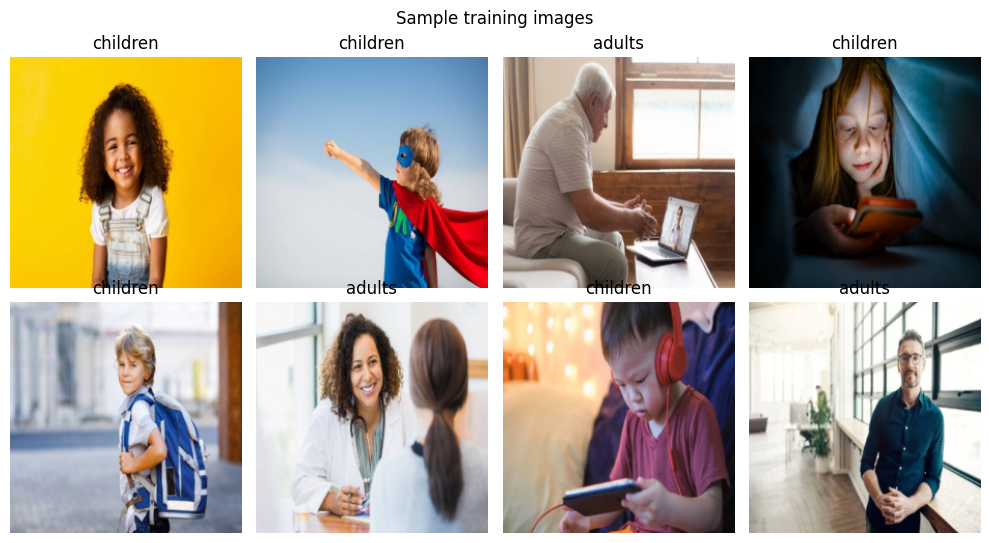

In [5]:
# A quick look at the data
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow((img * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1))   # undo normalisation
    ax.set_title(CLASS_NAMES[lab]); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

## 3. Training and evaluation utilities

One small set of functions is shared by every experiment so the comparisons are fair: same optimiser (Adam), same loss (`BCEWithLogitsLoss`, since this is a single-logit binary problem), same seed, and the weights from the **best validation epoch** are restored before testing.

Because the test set is small, I report **balanced accuracy** next to plain accuracy and print a per-class report. A model that predicts one class for everything can still score about 50% accuracy, and the per-class recall shows that immediately.

In [6]:
RESULTS = []   # every experiment appends a row here; summarised at the end

def run_epoch(model, loader, loss_fn, optimizer=None):
    """One pass over `loader`. Trains if an optimizer is given, otherwise just evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, n = 0.0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.float().unsqueeze(1).to(DEVICE)
            loss = loss_fn(model(x), y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            n += x.size(0)
    return total_loss / n

def fit(model, train_loader, val_loader, epochs=EPOCHS, lr=LR):
    """Train, keep the best-validation checkpoint, return (model, loss history)."""
    model.to(DEVICE)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    history = {"train": [], "val": []}
    best_val, best_state = float("inf"), None
    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, loss_fn, optimizer)
        va = run_epoch(model, val_loader, loss_fn)
        history["train"].append(tr); history["val"].append(va)
        if va < best_val:
            best_val = va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"epoch {epoch:02d} | train loss {tr:.4f} | val loss {va:.4f}")
    model.load_state_dict(best_state)
    return model, history

@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        probs = torch.sigmoid(model(x.to(DEVICE))).squeeze(1)
        y_pred += (probs >= 0.5).long().cpu().tolist()
        y_true += y.tolist()
    return y_true, y_pred

def evaluate(model, test_loader, class_names, experiment, variant):
    """Print a per-class report and record the headline metrics."""
    y_true, y_pred = predict(model, test_loader)
    acc, bal = accuracy_score(y_true, y_pred), balanced_accuracy_score(y_true, y_pred)
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
    print(f"accuracy {acc:.3f} | balanced accuracy {bal:.3f}")
    RESULTS.append({"experiment": experiment, "variant": variant,
                    "accuracy": acc, "balanced_accuracy": bal})

def plot_history(history, title):
    plt.plot(history["train"], label="train"); plt.plot(history["val"], label="validation")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(title); plt.legend(); plt.show()

## 4. Experiment 1: Activation functions

### The model
A VGG-style CNN built from scratch: six conv blocks (3x3 conv, batch norm, and max-pool after blocks 1, 2 and 6), then three dropout + fully-connected layers and a single-logit output. The activation function is a constructor argument and is applied after each of the three hidden fully-connected layers. I compare:

- **none**: no non-linearity in the head (baseline)
- **ReLU, SiLU, Sigmoid, Tanh, ELU**: the standard built-ins
- **Scaled softsign** (my own): `f(x) = x / (1 + alpha * |x|)`. It is smooth and bounded in `(-1/alpha, 1/alpha)` like tanh, but approaches its limits polynomially rather than exponentially, so gradients decay more gently for large inputs. Implemented from scratch, with no built-in PyTorch activation.

In [7]:
class ScaledSoftsign(nn.Module):
    """Custom activation: f(x) = x / (1 + alpha * |x|)."""
    def __init__(self, alpha=1.0):
        super().__init__()
        self.alpha = float(alpha)

    def forward(self, x):
        return x / (1.0 + self.alpha * torch.abs(x))

ACTIVATIONS = {
    "none": nn.Identity, "relu": nn.ReLU, "silu": nn.SiLU, "sigmoid": nn.Sigmoid,
    "tanh": nn.Tanh, "elu": nn.ELU, "scaled_softsign": ScaledSoftsign,
}

def conv_block(c_in, c_out, pool):
    layers = [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out)]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class DeepCNN(nn.Module):
    def __init__(self, activation="relu"):
        super().__init__()
        act = ACTIVATIONS[activation]
        self.features = nn.Sequential(                  # 224 -> 112 -> 56 -> 56 -> 56 -> 56 -> 28
            conv_block(3, 32, pool=True),
            conv_block(32, 256, pool=True),
            conv_block(256, 512, pool=False),
            conv_block(512, 256, pool=False),
            conv_block(256, 128, pool=False),
            conv_block(128, 64, pool=True),
        )
        def fc(n_in, n_out):
            return nn.Sequential(nn.Dropout(0.5), nn.Linear(n_in, n_out), act())
        self.classifier = nn.Sequential(
            nn.Flatten(),
            fc(64 * 28 * 28, 4096), fc(4096, 4096), fc(4096, 1000),
            nn.Linear(1000, 1),                          # single logit for BCEWithLogitsLoss
        )

    def forward(self, x):
        return self.classifier(self.features(x))

n_params = sum(p.numel() for p in DeepCNN().parameters())
print(f"DeepCNN has {n_params/1e6:.0f}M parameters")

DeepCNN has 229M parameters


In [8]:
act_histories = {}
for name in ACTIVATIONS:
    print(f"\n===== activation: {name} =====")
    set_seed()
    model, history = fit(DeepCNN(activation=name), train_loader, val_loader)
    act_histories[name] = history
    evaluate(model, test_loader, CLASS_NAMES, "Activation functions", name)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


===== activation: none =====
epoch 01 | train loss 118.5726 | val loss 27.6595
epoch 02 | train loss 14.4103 | val loss 2.9769
epoch 03 | train loss 1.9843 | val loss 4.2253
epoch 04 | train loss 1.6699 | val loss 1.7322
epoch 05 | train loss 1.1375 | val loss 1.1206
epoch 06 | train loss 1.0157 | val loss 0.8187
epoch 07 | train loss 1.4637 | val loss 2.9348
epoch 08 | train loss 1.4363 | val loss 0.8105
epoch 09 | train loss 1.0642 | val loss 0.9701
epoch 10 | train loss 0.8235 | val loss 0.7298
epoch 11 | train loss 0.7633 | val loss 1.5304
epoch 12 | train loss 1.0070 | val loss 1.5751
epoch 13 | train loss 0.9040 | val loss 0.9073
epoch 14 | train loss 0.7854 | val loss 0.6246
epoch 15 | train loss 0.8798 | val loss 1.1255
epoch 16 | train loss 1.2377 | val loss 0.7397
epoch 17 | train loss 0.8455 | val loss 0.8471
epoch 18 | train loss 0.7509 | val loss 0.7791
epoch 19 | train loss 0.8350 | val loss 0.7028
epoch 20 | train loss 0.8599 | val loss 1.0291
              precision   

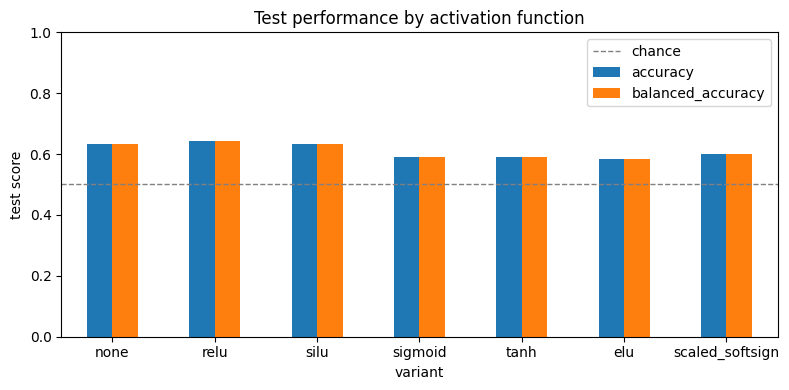

In [9]:
act_df = pd.DataFrame([r for r in RESULTS if r["experiment"] == "Activation functions"]).set_index("variant")
ax = act_df[["accuracy", "balanced_accuracy"]].plot.bar(figsize=(8, 4), rot=0, ylim=(0, 1))
ax.axhline(0.5, color="grey", ls="--", lw=1, label="chance")
ax.set_ylabel("test score"); ax.set_title("Test performance by activation function"); ax.legend()
import os; os.makedirs("figures", exist_ok=True)
plt.tight_layout()
plt.savefig("figures/activations.png", dpi=150, bbox_inches="tight")
plt.tight_layout(); plt.show()

### Reading the results

- **A loss stuck near 0.693 (= ln 2) means the network is outputting p ~ 0.5 for everything.** Check the per-class reports above: a run with 0.00 recall on one class has collapsed to predicting a single class.
- **Mind the noise.** The test set has only ~120 images, so one image is ~0.8 percentage points and the 95% interval on any accuracy is roughly +/-9 points. Gaps of a few points between activations are not meaningful; only large gaps (like a collapsed run) are.

> All seven variants landed between 56% and 67% test accuracy, and with 120 test images (a 95% interval of roughly ±9 points) most of those gaps are within noise. The head with no activation scored highest (66.7%), but its training loss started above 100 and stayed erratic, so I wouldn’t read that as “no activation is best”. ELU (55.8%) and SiLU (60.8%) were the weakest. Their training loss hovered near ln 2 (about 0.69), meaning they barely learned, and they leaned toward predicting “adult” (recall on children of only 0.17 and 0.33). ReLU overfit, with training loss falling to 0.37 while validation loss climbed past 1.5. Sigmoid and Tanh trained more gently and reached about 62%. My scaled softsign reached 56.7%, second-lowest: it learned (training loss fell to about 0.60) but did not beat the built-ins. The bigger lesson is that none of the from-scratch variants came close to the pretrained models in the next experiment.

## 5. Experiment 2: Transfer learning with ResNets

With so few training images, a network trained from scratch is data-starved. Here I start from ImageNet-pretrained **ResNet-18, 50 and 152**, replace the final layer with a single-logit head, and compare two regimes:

- **Frozen backbone**: only the new head is trained (fast, low risk of overfitting).
- **Full fine-tune**: every layer is updated.

The deeper the network, the more capacity (and the more data it usually wants), so the question is whether depth helps here at all.

In [10]:
def build_resnet(arch, freeze_backbone):
    model = getattr(models, arch)(weights="IMAGENET1K_V1")
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False          # note: the new head below is created trainable
    model.fc = nn.Linear(model.fc.in_features, 1)
    return model

for arch in ["resnet18", "resnet50", "resnet152"]:
    for mode, freeze in [("frozen backbone", True), ("full fine-tune", False)]:
        print(f"\n===== {arch} | {mode} =====")
        set_seed()
        model, history = fit(build_resnet(arch, freeze), train_loader, val_loader)
        evaluate(model, test_loader, CLASS_NAMES, "Transfer learning", f"{arch} ({mode})")
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


===== resnet18 | frozen backbone =====
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 153MB/s]


epoch 01 | train loss 0.6687 | val loss 0.5612
epoch 02 | train loss 0.5722 | val loss 0.5323
epoch 03 | train loss 0.5171 | val loss 0.4491
epoch 04 | train loss 0.4804 | val loss 0.4376
epoch 05 | train loss 0.4502 | val loss 0.4365
epoch 06 | train loss 0.4509 | val loss 0.4109
epoch 07 | train loss 0.4370 | val loss 0.4168
epoch 08 | train loss 0.4302 | val loss 0.4077
epoch 09 | train loss 0.3938 | val loss 0.3914
epoch 10 | train loss 0.4096 | val loss 0.4132
epoch 11 | train loss 0.3985 | val loss 0.4009
epoch 12 | train loss 0.4140 | val loss 0.3831
epoch 13 | train loss 0.3816 | val loss 0.3872
epoch 14 | train loss 0.3626 | val loss 0.4116
epoch 15 | train loss 0.3625 | val loss 0.3941
epoch 16 | train loss 0.3774 | val loss 0.4101
epoch 17 | train loss 0.3606 | val loss 0.3726
epoch 18 | train loss 0.3698 | val loss 0.4300
epoch 19 | train loss 0.3503 | val loss 0.4261
epoch 20 | train loss 0.3406 | val loss 0.3761
              precision    recall  f1-score   support

     

100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


epoch 01 | train loss 0.6542 | val loss 0.4986
epoch 02 | train loss 0.5060 | val loss 0.3898
epoch 03 | train loss 0.4494 | val loss 0.3500
epoch 04 | train loss 0.4242 | val loss 0.4062
epoch 05 | train loss 0.3848 | val loss 0.3242
epoch 06 | train loss 0.3765 | val loss 0.3100
epoch 07 | train loss 0.3468 | val loss 0.3260
epoch 08 | train loss 0.3456 | val loss 0.3213
epoch 09 | train loss 0.3587 | val loss 0.3235
epoch 10 | train loss 0.3841 | val loss 0.3941
epoch 11 | train loss 0.3079 | val loss 0.2999
epoch 12 | train loss 0.3261 | val loss 0.3008
epoch 13 | train loss 0.3288 | val loss 0.3202
epoch 14 | train loss 0.3035 | val loss 0.3340
epoch 15 | train loss 0.2824 | val loss 0.3035
epoch 16 | train loss 0.3036 | val loss 0.3124
epoch 17 | train loss 0.3260 | val loss 0.3658
epoch 18 | train loss 0.2821 | val loss 0.3040
epoch 19 | train loss 0.2863 | val loss 0.3006
epoch 20 | train loss 0.2765 | val loss 0.3011
              precision    recall  f1-score   support

     

100%|██████████| 230M/230M [00:02<00:00, 109MB/s]


epoch 01 | train loss 0.6311 | val loss 0.5229
epoch 02 | train loss 0.4878 | val loss 0.3954
epoch 03 | train loss 0.4121 | val loss 0.3527
epoch 04 | train loss 0.4642 | val loss 0.3509
epoch 05 | train loss 0.3669 | val loss 0.3191
epoch 06 | train loss 0.3517 | val loss 0.3182
epoch 07 | train loss 0.3686 | val loss 0.3120
epoch 08 | train loss 0.3653 | val loss 0.2968
epoch 09 | train loss 0.3480 | val loss 0.3188
epoch 10 | train loss 0.3444 | val loss 0.2948
epoch 11 | train loss 0.3438 | val loss 0.3383
epoch 12 | train loss 0.3190 | val loss 0.2963
epoch 13 | train loss 0.3340 | val loss 0.3136
epoch 14 | train loss 0.3061 | val loss 0.3159
epoch 15 | train loss 0.3168 | val loss 0.3317
epoch 16 | train loss 0.3387 | val loss 0.2849
epoch 17 | train loss 0.2983 | val loss 0.2857
epoch 18 | train loss 0.2909 | val loss 0.3005
epoch 19 | train loss 0.2691 | val loss 0.2878
epoch 20 | train loss 0.2738 | val loss 0.2875
              precision    recall  f1-score   support

     

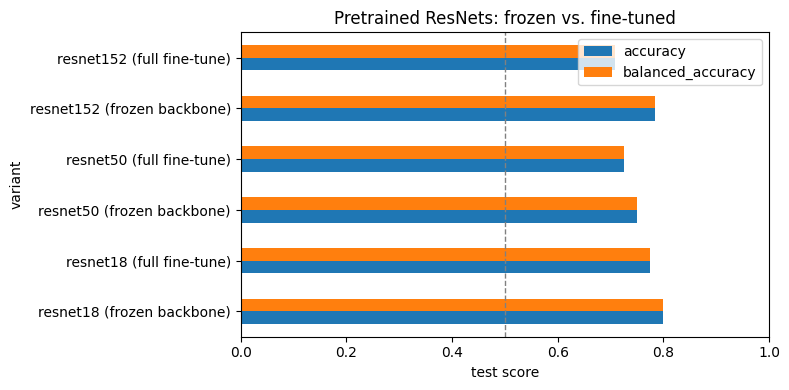

In [11]:
tl_df = pd.DataFrame([r for r in RESULTS if r["experiment"] == "Transfer learning"]).set_index("variant")
ax = tl_df[["accuracy", "balanced_accuracy"]].plot.barh(figsize=(8, 4), xlim=(0, 1))
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("test score"); ax.set_title("Pretrained ResNets: frozen vs. fine-tuned")
plt.tight_layout()
plt.savefig("figures/resnets.png", dpi=150, bbox_inches="tight")
plt.tight_layout(); plt.show()

> ResNet-18, the smallest model, was the best overall at 80.0% test accuracy in both modes, with the frozen ResNet-152 (78.3%) within noise of it. Freezing mattered most for the deeper networks. ResNet-50 dropped from 75.0% frozen to 61.7% fully fine-tuned, and ResNet-152 from 78.3% to 70.8%, while ResNet-18 was unchanged. The loss curves show why. Fine-tuned runs drove training loss near zero while validation loss spiked (4.5 for ResNet-18 at epoch 4, over 100 for ResNet-152 at epoch 1). That points to overfitting and instability from updating 11–60 million parameters with 544 images at a learning rate of 1e-3, which is probably too high for fine-tuning. Frozen runs trained and validated in step. Against the best from-scratch CNN (66.7%), pretrained features added about 13 points, the largest gain in the project. With this little data, ImageNet features plus a linear head were enough, and extra depth did not help.

## 6. Experiment 3: Class imbalance

Real datasets are rarely balanced. Here the training set has far fewer children than adults (roughly 4:1 in my split). A classifier can score well on plain accuracy just by favouring the majority class, so I judge this experiment on **balanced accuracy** and per-class recall.

I train the same small two-block CNN twice: once on the data as-is, and once with a `WeightedRandomSampler`, which draws minority-class images more often (with replacement) so each batch is roughly balanced.

In [12]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 56 * 56, 1))

    def forward(self, x):
        return self.classifier(self.features(x))

def class_counts(root):
    ds = datasets.ImageFolder(root)
    return {ds.classes[k]: v for k, v in sorted(Counter(ds.targets).items())}

print("balanced train  :", class_counts(BALANCED_TRAIN))
print("imbalanced train:", class_counts(IMBALANCED_TRAIN))

balanced train  : {'adults': 340, 'children': 340}
imbalanced train: {'adults': 341, 'children': 82}



===== imbalanced data, no sampler =====
train 338 | val 85 | test 120 | classes ['adults', 'children']
epoch 01 | train loss 6.3149 | val loss 1.1448
epoch 02 | train loss 1.5875 | val loss 1.3057
epoch 03 | train loss 0.9141 | val loss 2.7038
epoch 04 | train loss 0.3588 | val loss 2.1161
epoch 05 | train loss 0.3066 | val loss 1.8300
epoch 06 | train loss 0.1008 | val loss 1.7526
epoch 07 | train loss 0.5794 | val loss 2.4066
epoch 08 | train loss 0.0921 | val loss 2.4821
epoch 09 | train loss 0.1094 | val loss 2.1461
epoch 10 | train loss 0.0403 | val loss 2.3374
epoch 11 | train loss 0.0196 | val loss 2.3218
epoch 12 | train loss 0.3317 | val loss 3.3686
epoch 13 | train loss 0.2744 | val loss 2.7767
epoch 14 | train loss 0.2619 | val loss 2.5693
epoch 15 | train loss 0.1226 | val loss 2.3531
epoch 16 | train loss 0.0123 | val loss 3.3554
epoch 17 | train loss 0.0063 | val loss 2.1438
epoch 18 | train loss 0.0359 | val loss 3.1208
epoch 19 | train loss 0.0218 | val loss 3.2190
epo

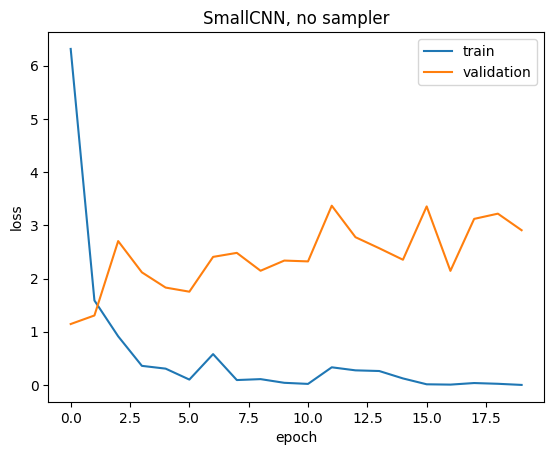

              precision    recall  f1-score   support

      adults       0.58      0.83      0.68        60
    children       0.71      0.40      0.51        60

    accuracy                           0.62       120
   macro avg       0.64      0.62      0.60       120
weighted avg       0.64      0.62      0.60       120

accuracy 0.617 | balanced accuracy 0.617

===== imbalanced data, with WeightedRandomSampler =====
train 338 | val 85 | test 120 | classes ['adults', 'children']
epoch 01 | train loss 4.6868 | val loss 2.0908
epoch 02 | train loss 1.4139 | val loss 6.7457
epoch 03 | train loss 1.6204 | val loss 7.3300
epoch 04 | train loss 1.5387 | val loss 2.0869
epoch 05 | train loss 0.4132 | val loss 3.1861
epoch 06 | train loss 0.1429 | val loss 2.6102
epoch 07 | train loss 0.3659 | val loss 2.5364
epoch 08 | train loss 0.0205 | val loss 2.0901
epoch 09 | train loss 0.0834 | val loss 2.5122
epoch 10 | train loss 0.0308 | val loss 2.2372
epoch 11 | train loss 0.0494 | val loss 2.

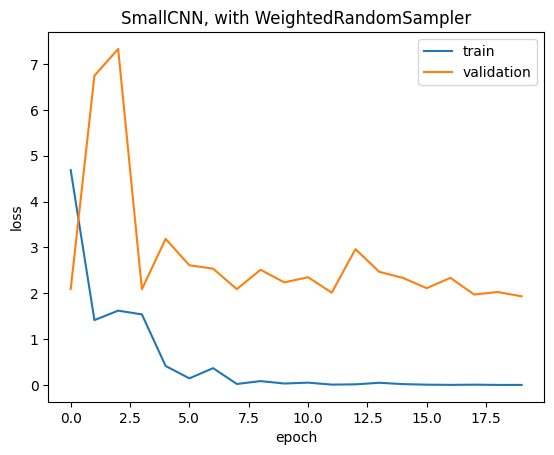

              precision    recall  f1-score   support

      adults       0.56      0.98      0.71        60
    children       0.93      0.22      0.35        60

    accuracy                           0.60       120
   macro avg       0.74      0.60      0.53       120
weighted avg       0.74      0.60      0.53       120

accuracy 0.600 | balanced accuracy 0.600


In [13]:
for use_sampler in [False, True]:
    label = "with WeightedRandomSampler" if use_sampler else "no sampler"
    print(f"\n===== imbalanced data, {label} =====")
    set_seed()
    tr, va, te, names = make_loaders(IMBALANCED_TRAIN, IMBALANCED_TEST, balance_classes=use_sampler)
    model, history = fit(SmallCNN(), tr, va)
    plot_history(history, f"SmallCNN, {label}")
    evaluate(model, te, names, "Class imbalance", label)

The training split is about 4:1 (341 adults vs. 82 children). Without a sampler, the model reached 61.7% accuracy, but only 40% recall on children against 83% on adults, so it leaned toward the majority class as expected. With the WeightedRandomSampler, children recall rose to 67%, adult recall fell to 62%, and accuracy edged up to 64.2%. The 2.5-point gain is only three images and well within noise, so the meaningful change is that errors became evenly split across the two classes instead of favouring adults. Oversampling only repeats the same 82 minority images and adds no new information, which is why both models still overfit badly: training loss fell to nearly zero while validation loss stayed high (about 1.8 without the sampler, about 2.3 with it). In both runs the best validation epoch was the very first one, so the restored checkpoints are barely trained. Augmentation would be a better fix than resampling alone, since it creates new variants of the scarce class.

## 7. Results summary

In [14]:
summary = pd.DataFrame(RESULTS).round(3)
summary.to_csv("results.csv", index=False)
summary

,experiment,variant,accuracy,balanced_accuracy
0,Activation functions,none,0.633,0.633
1,Activation functions,relu,0.642,0.642
2,Activation functions,silu,0.633,0.633
3,Activation functions,sigmoid,0.592,0.592
4,Activation functions,tanh,0.592,0.592
5,Activation functions,elu,0.583,0.583
6,Activation functions,scaled_softsign,0.600,0.600
7,Transfer learning,resnet18 (frozen backbone),0.800,0.800
8,Transfer learning,resnet18 (full fine-tune),0.775,0.775
9,Transfer learning,resnet50 (frozen backbone),0.750,0.750


## 8. Takeaways and next steps

Weighted sampling rebalanced per-class recall (children 40% → 67%) at no real cost in overall accuracy, but it doesn’t add information. Both imbalance models overfit heavily, so augmentation is the natural next step.

**Things I would try next**

- **Shrink the model.** Over 89% of `DeepCNN`'s ~229M parameters sit in the first fully-connected layer (50,176 x 4,096). Global average pooling before the head would cut this dramatically and likely reduce overfitting.
- **Data augmentation.** Random flips, rotations, colour jitter and noise are the standard answer to a small dataset and are a more principled complement to oversampling for the imbalance problem.
- **Match the pretrained normalisation.** The ResNets were trained with ImageNet mean/std; I reused the same [-1, 1] normalisation as the scratch models to keep comparisons controlled, but ImageNet statistics would be the better choice for transfer learning.
- **Activations in the conv blocks.** I only varied the activation in the fully-connected head; applying it inside the conv blocks is a natural extension.
- **Repeat over several seeds** and report mean +/- std, since single runs on ~120 test images are noisy.

---
*Dataset: Kaggle, "Children vs. Adults Images". Originally a CMPUT 466/566 course project; code restructured and extended.*